# Biogas TSMixer model driver

### The purpose of this notebook is to present an example of how to use the model and to compare it with sample experimental data.

#### 1. Importing necessary libraries (the script assumes that the specified libraries are already installed in the computing environment)

In [1]:
import pickle
import warnings
import logging
import matplotlib.pyplot as plt

from BTS_helper import historical_forecasts, load_all_models

#### 2. Loading deployed models and test data

In [ ]:
step_intervals = [8, 16, 24, 32, 40]
with open('test_dataset.pkl', 'rb') as f:
    loaded_data = pickle.load(f)

series = loaded_data['series']
scaler = loaded_data['scaler']

models_dict = load_all_models("TSMixer_models.dep", step_intervals)

#### 3. Generating forecasts

In [3]:
for logger_name in ["pytorch_lightning", "darts"]:
    logging.getLogger(logger_name).setLevel(logging.ERROR)
warnings.filterwarnings("ignore", module=".*pytorch_lightning.*", category=UserWarning)

forecasts_list = []
for interval in step_intervals:
    model_key = f"tsmixer_model_{interval}"
    model = models_dict[interval]

    forecast = historical_forecasts(model, series, interval, scaler)
    forecasts_list.append(forecast)

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

#### 4. Comparing with experimental data

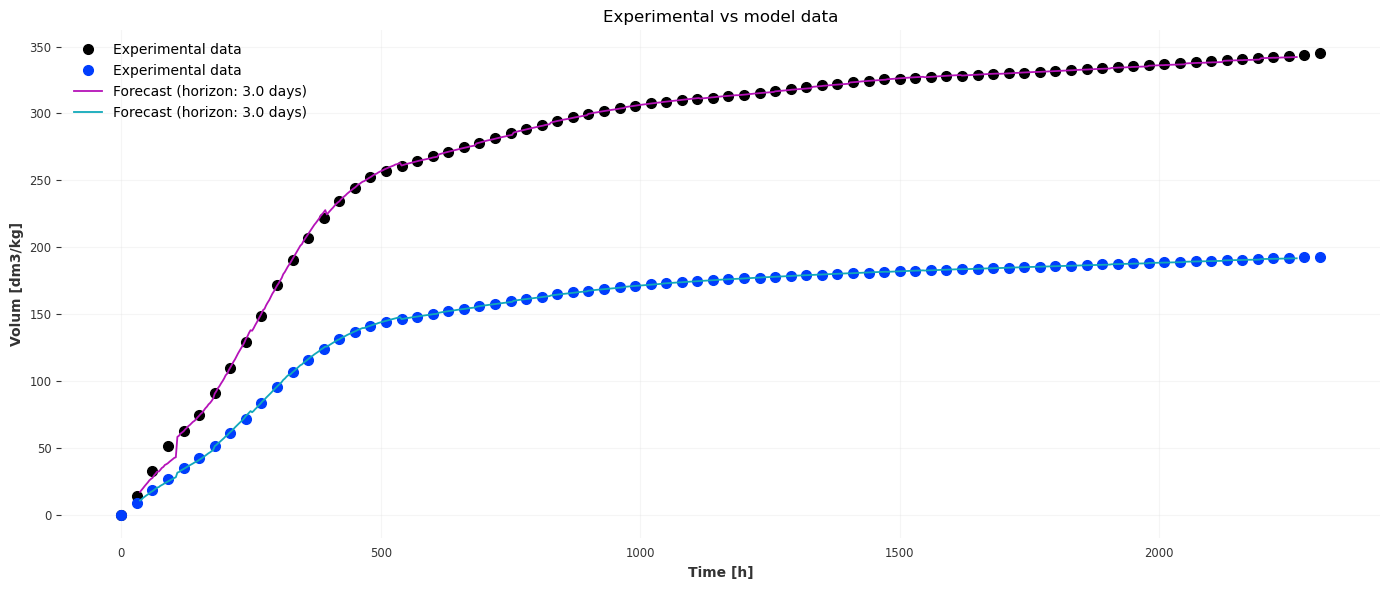

In [13]:
#Horizon to show on plot: 8, 16, 24, 32 or 40h
horizon = 24
forecast = forecasts_list[step_intervals.index(horizon)]
series_raw = scaler.inverse_transform(series)

start_time = series.time_index[0]
time_raw_hours = (series_raw.time_index - start_time).total_seconds() / 3600
time_forecast_hours = (forecast.time_index - start_time).total_seconds() / 3600

plt.figure(figsize=(14, 6))
plt.plot(
    time_raw_hours[::10],
    series_raw[::10].values().squeeze(),
    label="Experimental data",
    marker="o",
    linestyle="None",
    markersize=7,
)

# Wykres prognozy
plt.plot(
    time_forecast_hours,
    forecast.values().squeeze(),
    label=f"Forecast (horizon: {horizon/8} days)",
)

plt.title("Experimental vs model data")
plt.xlabel("Time [h]")
plt.ylabel("Volum [dm3/kg]")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()